In [103]:
from langgraph.graph import StateGraph, START, END
from typing import Annotated, TypedDict
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_groq import ChatGroq
from langgraph.graph.message import add_messages
from dotenv import load_dotenv

from langgraph.prebuilt import ToolNode, tools_condition
from langchain_core.tools import tool
from langchain_community.tools import DuckDuckGoSearchRun

import requests
import random

In [104]:
load_dotenv()

True

In [105]:
chat_model1 = ChatGroq(
    model="llama-3.1-8b-instant",
    temperature=0,
)

In [106]:
# Tools
search_tool = DuckDuckGoSearchRun(region="us-en")

@tool
def calculator(first_num : float, second_num : float, operation : str) -> dict :
    """
    Perform a basic arithmetic operation on two numbers.
    Support operations : add, sub, mul, div
    """
    try : 
        if operation == 'add' :
            result = first_num + second_num
        elif operation == 'sub' :
            result = first_num - second_num
        elif operation == 'mul' :
            result = first_num * second_num
        elif operation == 'div' :
            if second_num == 0 :
                return {"error" : "Division by zero is not allowed"}
            result = first_num/second_num
        else : 
            return {"error" : f"Unsupported operation '{operation}'"}

        return {"first number" : first_num, "Second number" : second_num, "Operation" : operation, "Result" : result}
    except Exception as e :
        return {"error" : str(e)}

@tool
def get_stock_price(symbol : str) -> dict :
    """
    Fetch latest stock price for a given symbol (e.g. 'AAPL', 'TSLA')
    using Alpha Vantage with API key in the URL.
    """
    url = f'https://www.alphavantage.co/query?function=GLOBAL_QUOTE&symbol={symbol}&interval=5min&apikey= WOOGZ31BEOPHGT6T'
    r = requests.get(url)
    return r.json()

In [107]:
# Make tool list
tools = [get_stock_price, search_tool, calculator]

# Make the LLM tool-aware
llm_with_tools = chat_model1.bind_tools(tools)

In [108]:
# State
class ChatState(TypedDict) :
    messages : Annotated[list[BaseMessage], add_messages]

In [109]:
# Graph nodes
def chat_node(state : ChatState) :
    """LLM node that may answer or request a tool call."""
    messages = state['messages']
    response = llm_with_tools.invoke(messages)
    return {"messages" : [response]}

tool_node = ToolNode(tools)  #Executes tool calls

In [110]:
# Graph Structure
graph = StateGraph(ChatState)

# Nodes
graph.add_node('Chat_Node', chat_node)
graph.add_node('tools', tool_node)

# Edges
graph.add_edge(START, 'Chat_Node')

# if the LLM asked for a tool, go to ToolNode; else : finish
graph.add_conditional_edges('Chat_Node', tools_condition)

graph.add_edge('tools', 'Chat_Node')

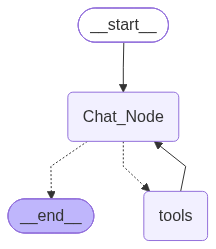

In [111]:
chatbot = graph.compile()

chatbot

In [98]:
# Regular chat
out = chatbot.invoke({'messages' : [HumanMessage(content="Hello!")]})

print(out["messages"][-1].content)

I'm happy to help you with any questions or tasks you have. What would you like to do first?


In [99]:
# Chat requiring tool
out = chatbot.invoke({'messages' : [HumanMessage(content="What is 2*3")]})

print(out['messages'][-1].content)

{"first number": 2.0, "Second number": 3.0, "Operation": "mul", "Result": 6.0}


In [112]:
# Chat requiring tool
out = chatbot.invoke({'messages' : [HumanMessage(content="What is the stock price of the AAPL")]})

print(out['messages'][-1].content)

The stock price of AAPL is $305.93.


In [113]:
# Chat requiring more than one tool
out = chatbot.invoke({'messages' : [HumanMessage(content="What is the stock price of the Apple. How much price for 3 stock")]})

print(out['messages'][-1].content)

The current stock price of Apple is $305.93. The price for 3 stocks is $576.72.
